# Master notebook — EDA of every dataset, then one merged table

**Biointerphase 1A · Forecasting Harmful Algal Bloom (HAB) risk · Break Through Tech AI Studio, Fall 2026**

This notebook goes through the nine project datasets one at a time — what each one is, profiling checks (rows, coverage, missing values, duplicates, invalid values), a few plots, and the cleaning decision — and ends by merging them into the **weekly modelling table** the models are trained on.

| Filename | Website/Source | Dates | Data Included |
|---|---|---|---|
| `habsos_cellcounts` | https://www.ncei.noaa.gov/products/harmful-algal-blooms-observing-system | 1953 – May 2026 | Latitude, Longitude, Date, Category, Cell Count, Salinity, Water Temp (*K. brevis* only) |
| `ChlorophyllaConcentrationSarasota` + `_Dataset2` | https://coastwatch.noaa.gov/cwn/products/noaa-msl12-multi-sensor-dineof-global-2-km-gap-filled-products-chlorophyll-diffuse.html | 2010 – Sep 2026 (file 1: Jun 2020 – Sep 2026; file 2: Jan 2010 – May 2022) | Latitude, Longitude, Date, Chlorophyll-a (lat 26.5–28, lon −83.5 to −81.8); file 2 is a coarser NOAA CoastWatch product whose exact source isn't documented |
| `NutrientsFL_2006_2025` | https://sarasota.wateratlas.usf.edu/water-quality-trends/ | 1998 – Dec 2025 | Date, Time, Depth; BOD, Chlorophyll-a (pheophytin corrected), DO, DO saturation, Fecal Coliform, Total Nitrogen, Ammonia (N), Kjeldahl Nitrogen, NO₂+NO₃ (N), pH, Total Phosphorus, Phosphate (PO₄), Specific Conductance, Water Temperature, TSS, Turbidity |
| `bradentonFL_tempData` | https://climatecenter.fsu.edu/climate-data-access-tools/downloadable-data | 2015 – 2025 | Date, Precipitation, Max Air Temp, Min Air Temp, Mean Air Temp |
| `Sarasota_Wind&Temp` | https://erddap.secoora.org/erddap/tabledap/gov_noaa_awc_ksrq.html | Jul 2022 – Jun 2026 | Air pressure, air temp, dew point temp, visibility, wind gust speed, wind speed, wind direction |
| `SarasotaWindData` | https://coastwatch.pfeg.noaa.gov/erddap/griddap/pifscCcmpDailyV21NRT.html (CCMP v2.1 NRT) | Jan 2019 – Sep 2026 | Latitude, Longitude, Date, East-west wind (u) |
| `MoteMarine_BottomTemp` | https://erddap.secoora.org/erddap/tabledap/org_secoora_scan_rng_sw.html | Aug 2020 – Mar 2025 | Latitude, Longitude, Date, Depth, Water Temp |
| `chirps20GlobalDailyP05_0878_d358_0bc6` | https://coastwatch.pfeg.noaa.gov/erddap/griddap/chirps20GlobalDailyP05.html | 2016 – 2026 (values only in 2016, 2020, 2024) | Latitude, Longitude, Date, Precipitation (land only) |
| `florida_cyanotoxins_2015-01-01_to_2026-06-17` | https://storymaps.arcgis.com/stories/ccc4c98425194605924ae474fb8002ba | 2015 – 2026 | Latitude, Longitude, Location Type, Date, Depth of Measurement, Cyanotoxin Type, Cyanotoxin Concentration, Detection Limit |

## 0. Setup

In [1]:
import os, sys, subprocess
from pathlib import Path

DATA_SOURCE = os.environ.get("HAB_DATA_SOURCE", "drive")      # "drive" | "github" | "local"
DRIVE_DATA_DIR = "/content/drive/MyDrive/BTT Fall AI Studio 2026/Google Colab/data"
GITHUB_REPO = "https://github.com/Break-Through-Tech/Biointerphase-1A-forecasting-harmful-algal-bloom-risk"
LOCAL_DATA_DIR = os.environ.get("HAB_DATA_DIR", str(Path("..") / ".." / "data"))  # the repo's data/ folder

IN_COLAB = "google.colab" in sys.modules

if DATA_SOURCE == "drive":
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR = Path(DRIVE_DATA_DIR)
    OUTPUT_DIR = DATA_DIR.parent / "outputs"
elif DATA_SOURCE == "github":
    repo_dir = Path("/content" if IN_COLAB else ".") / "hab_repo"
    if not repo_dir.exists():
        # Clone without the large files, then pull only the CSVs (skips ~750 MB of duplicate JSON).
        subprocess.run("git lfs install", shell=True, check=True)
        subprocess.run(f"git clone --depth 1 {GITHUB_REPO} {repo_dir}", shell=True, check=True,
                       env={**os.environ, "GIT_LFS_SKIP_SMUDGE": "1"})
        subprocess.run('git lfs pull --include "data/*.csv"', shell=True, check=True, cwd=repo_dir)
    DATA_DIR = repo_dir / "data"
    OUTPUT_DIR = repo_dir / "outputs"
else:
    DATA_DIR = Path(LOCAL_DATA_DIR)
    OUTPUT_DIR = Path("outputs")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("data from:", DATA_DIR)
print("outputs to:", OUTPUT_DIR)
print("files:", sorted(p.name for p in DATA_DIR.iterdir() if p.suffix in (".csv", ".txt")))

data from: ..\..\data
outputs to: outputs
files: ['ChlorophyllaConcentrationSarasota.csv', 'ChlorophyllaConcentrationSarasota_Dataset2.csv', 'MoteMarine_BottomTemp.csv', 'NutrientsFL_2006_2025.csv', 'SarasotaWindData.csv', 'Sarasota_Wind&Temp.csv', 'bradentonFL_tempData.csv', 'chirps20GlobalDailyP05_0878_d358_0bc6.csv', 'florida_cyanotoxins_2015-01-01_to_2026-06-17.csv', 'habsos_cellcounts.csv']


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", None)   # show cleaning-log notes in full
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "0.92"})

# --- Study design (shared by every section) --------------------------------
# Target box: Sarasota County coast, Anna Maria Island (27.5 N) to Englewood (26.9 N), ~45 km offshore.
TARGET_BOX = dict(lat=(26.9, 27.6), lon=(-83.0, -82.3))
# Wider box for "what is happening nearby" (blooms drift in from the south/offshore; Medina et al. 2024).
REGIONAL_BOX = dict(lat=(26.3, 28.0), lon=(-83.5, -81.8))
CLASS_EDGES = [0, 1e4, 1e5]                    # no bloom | at risk | bloom
CLASS_NAMES = ["no_bloom", "at_risk", "bloom"]
WEEK_RULE = "W-SUN"                            # weeks end on Sunday
STUDY_START = "2010-01-01"                     # satellite chlorophyll begins Jan 2010
HORIZON_WEEKS = 1                              # label = class in week t+1


def find_file(stem: str) -> Path:
    """Find a project data file by name, whatever its extension.

    The same file ends in .csv in the GitHub repo but sometimes .txt on Drive.

    Args:
        stem (str): File name without extension, e.g. "habsos_cellcounts".

    Returns:
        pathlib.Path: Path to the first matching file in DATA_DIR.

    Raises:
        FileNotFoundError: If neither stem.csv nor stem.txt exists in DATA_DIR.

    Example:
        >>> find_file("habsos_cellcounts").name
        'habsos_cellcounts.csv'
    """
    for ext in (".csv", ".txt"):
        p = DATA_DIR / f"{stem}{ext}"
        if p.exists():
            return p
    raise FileNotFoundError(f"{stem}.csv/.txt not found in {DATA_DIR}")


def read_erddap(stem: str, **kw) -> pd.DataFrame:
    """Read an ERDDAP CSV export, skipping its units row.

    ERDDAP puts a row of units (e.g. "UTC", "degrees_north") directly under the
    header; read as data it would turn every column into text.

    Args:
        stem (str): File name without extension.
        **kw: Extra keyword arguments passed to pandas.read_csv (e.g. usecols, dtype).

    Returns:
        pandas.DataFrame: The file's rows with the units row removed.

    Example:
        >>> read_erddap("MoteMarine_BottomTemp").columns[0]
        'time'
    """
    return pd.read_csv(find_file(stem), skiprows=[1], **kw)


def is_in_box(lat: pd.Series, lon: pd.Series, box: dict) -> pd.Series:
    """Flag rows whose coordinates fall inside a latitude/longitude box.

    Args:
        lat (pandas.Series): Latitudes in degrees north.
        lon (pandas.Series): Longitudes in degrees east, -180..180.
        box (dict): {"lat": (min, max), "lon": (min, max)}, bounds inclusive.

    Returns:
        pandas.Series: Boolean mask, True where the point is inside the box.

    Example:
        >>> is_in_box(pd.Series([27.3, 28.5]), pd.Series([-82.6, -82.6]), TARGET_BOX).tolist()
        [True, False]
    """
    return lat.between(*box["lat"]) & lon.between(*box["lon"])


def profile_columns(df: pd.DataFrame) -> pd.DataFrame:
    """Summarise every column of a DataFrame for a first data-quality look.

    Args:
        df (pandas.DataFrame): The table to profile.

    Returns:
        pandas.DataFrame: One row per column with its dtype, missing count,
            missing percentage, number of distinct values and one example value.

    Example:
        >>> profile_columns(pd.DataFrame({"a": [1, None, 1]}))[["missing", "distinct"]].values.tolist()
        [[1, 1]]
    """
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing": df.isna().sum(),
        "missing_%": (100 * df.isna().mean()).round(1),
        "distinct": df.nunique(),
        # First non-null value, so a column that is mostly empty still shows what it holds.
        "example": [df[c].dropna().iloc[0] if df[c].notna().any() else None for c in df.columns],
    })


def plot_per_year(dates: pd.Series, title: str, ax: plt.Axes | None = None, color: str = "tab:blue") -> pd.Series:
    """Bar chart of how many rows fall in each calendar year.

    Args:
        dates (pandas.Series): Datetime values, one per row.
        title (str): Chart title.
        ax (matplotlib.axes.Axes, optional): Axes to draw on; a new figure is made if None.
        color (str): Bar colour.

    Returns:
        pandas.Series: Row count per year, indexed by year.

    Example:
        >>> plot_per_year(pd.Series(pd.to_datetime(["2020-01-05", "2020-06-01", "2021-03-02"])), "Rows per year").tolist()
        [2, 1]
    """
    counts = dates.dt.year.value_counts().sort_index()
    ax = ax or plt.subplots(figsize=(11, 2.8))[1]
    counts.plot(kind="bar", ax=ax, color=color, width=0.85)
    ax.set_title(title); ax.set_xlabel(""); ax.set_ylabel("rows")
    return counts


# Cleaning log: every section records rows kept per step -> the "100% -> x%" table at the end.
LOG = []


def log_step(dataset: str, step: str, n: int | pd.DataFrame, note: str = "") -> None:
    """Record how many rows of a dataset remain after a cleaning step.

    Appends to the global LOG list, which becomes the cleaning-log table in §10.

    Args:
        dataset (str): Dataset name, e.g. "habsos_cellcounts".
        step (str): Short description of the step, e.g. "QA flag == 1".
        n (int or sized): Row count, or any object with a length (a DataFrame).
        note (str): Optional reason or caveat shown in the log.

    Returns:
        None

    Example:
        >>> log_step("MoteMarine_BottomTemp", "raw", 31729)
        >>> LOG[-1]["rows"]
        31729
    """
    n = n if isinstance(n, (int, np.integer)) else len(n)
    LOG.append(dict(dataset=dataset, step=step, rows=int(n), note=note))


def show_step(dataset: str, before: pd.DataFrame, after: pd.DataFrame, label: str) -> None:
    """Print how many rows a cleaning step kept and removed, and record it in the log.

    Args:
        dataset (str): Dataset name used in the cleaning log.
        before (pandas.DataFrame): Table before the step.
        after (pandas.DataFrame): Table after the step.
        label (str): Short description of the step.

    Returns:
        None

    Example:
        >>> show_step("habsos_cellcounts", h2, h3, "drop duplicates")
        drop duplicates: 218,960 -> 217,024 rows  (removed 1,936)
    """
    diff = len(before) - len(after)
    change = f"removed {diff:,}" if diff >= 0 else f"added {-diff:,}"
    print(f"{label}: {len(before):,} -> {len(after):,} rows  ({change})")
    log_step(dataset, label, after)


def summarise_cleaning(dataset: str, subset_steps: tuple = ()) -> pd.DataFrame:
    """Table of rows kept after each logged cleaning step of one dataset.

    Args:
        dataset (str): Dataset name as used in log_step / show_step.
        subset_steps (iterable of str): Steps that select a subset for reporting
            (e.g. "of which inside target box") rather than remove rows; their
            "removed" value is shown as 0.

    Returns:
        pandas.DataFrame: One row per step with rows kept, rows removed and
            percentage of the first logged step.

    Example:
        >>> summarise_cleaning("MoteMarine_BottomTemp")["rows"].tolist()
        [31729, 31629, 31629]
    """
    s = pd.DataFrame([r for r in LOG if r["dataset"] == dataset])
    removed = (-s["rows"].diff()).fillna(0).astype(int)
    removed[s["step"].isin(subset_steps)] = 0
    # A negative change means the step added rows (e.g. re-gridding); say so instead of showing a minus sign.
    s["removed"] = [f"{r:,}" if r >= 0 else f"{-r:,} added" for r in removed]
    s["% of raw"] = (100 * s["rows"] / s["rows"].iloc[0]).round(1)
    return s[["step", "rows", "removed", "% of raw"] + (["note"] if s["note"].astype(bool).any() else [])]

---
## 1. `habsos_cellcounts` — *K. brevis* cell counts (the label)

| | |
|---|---|
| **What** | Water samples counted under a microscope for *Karenia brevis*, the red-tide dinoflagellate |
| **Source** | NOAA HABSOS / Florida Fish and Wildlife Conservation Commission (FWC) |
| **Coverage** | 1953 – May 2026, Gulf of Mexico (mostly Florida) |
| **Role** | The **label** (weekly maximum count in the Sarasota box) and the bloom-history features |

**This section:** 1.1 load and first look · 1.2 data-quality checks · 1.3 the five HABSOS categories · 1.4 exploring the data · 1.5 findings · 1.6 cleaning, step by step · 1.7 cleaning summary

### 1.1 Load and first look
One row per water sample: where (latitude, longitude, site description), when, how deep, the cell count, and optional salinity / water temperature / wind readings taken with the sample.

In [3]:
habsos_raw = pd.read_csv(find_file("habsos_cellcounts"), low_memory=False)
habsos_raw["date"] = pd.to_datetime(habsos_raw["SAMPLE_DATE"], errors="coerce")
print(f"{len(habsos_raw):,} rows x {habsos_raw.shape[1]} columns")
habsos_raw.head(3)

219,152 rows x 27 columns


,OBJECTID,DESCRIPTION,LATITUDE,LONGITUDE,STATE_ID,SAMPLE_DATE,SAMPLE_DEPTH,GENUS,SPECIES,CATEGORY,CELLCOUNT,CELLCOUNT_UNIT,CELLCOUNT_QA,SALINITY,SALINITY_UNIT,SALINITY_QA,WATER_TEMP,WATER_TEMP_UNIT,WATER_TEMP_QA,WIND_DIR,WIND_DIR_UNIT,WIND_DIR_QA,WIND_SPEED,WIND_SPEED_UNIT,WIND_SPEED_QA,QA_COMMENT,date
0,1,Tom Adams Bridge (Lemon Bay),26.93450,-82.3535,FL,1953-08-19 00:00:00,0.5,Karenia,brevis,medium,116000.0,cells/L,1,NaN,NaN,9,NaN,NaN,9,NaN,NaN,9,NaN,NaN,9,Missing/invalid time of day,1953-08-19
1,2,Naples Pier,26.13163,-81.8063,FL,1953-08-26 00:00:00,0.5,Karenia,brevis,not observed,0.0,cells/L,1,NaN,NaN,9,NaN,NaN,9,NaN,NaN,9,NaN,NaN,9,Missing/invalid time of day,1953-08-26
2,3,Piney Point; Lee County,26.53340,-81.9796,FL,1953-08-26 00:00:00,0.5,Karenia,brevis,not observed,0.0,cells/L,1,NaN,NaN,9,NaN,NaN,9,NaN,NaN,9,NaN,NaN,9,Missing/invalid time of day,1953-08-26


**Column overview** — type, how much is missing, how many distinct values, and an example of each column:

In [4]:
profile_columns(habsos_raw)

,dtype,missing,missing_%,distinct,example
OBJECTID,int64,0,0.0,219152,1
DESCRIPTION,str,3088,1.4,29889,Tom Adams Bridge (Lemon Bay)
LATITUDE,float64,0,0.0,30478,26.9345
LONGITUDE,float64,0,0.0,30061,-82.3535
STATE_ID,str,0,0.0,4,FL
SAMPLE_DATE,str,0,0.0,147172,1953-08-19 00:00:00
SAMPLE_DEPTH,float64,6220,2.8,635,0.5
GENUS,str,0,0.0,1,Karenia
SPECIES,str,0,0.0,1,brevis
CATEGORY,str,856,0.4,5,medium


### 1.2 Data-quality checks
Each check asks one question about the raw file; the answer decides whether a cleaning step is needed in 1.6.

In [5]:
both_missing = habsos_raw["SALINITY"].isna() & habsos_raw["WATER_TEMP"].isna()
dup_key = ["LATITUDE", "LONGITUDE", "SAMPLE_DATE", "SAMPLE_DEPTH", "CELLCOUNT"]
checks = pd.DataFrame([
    ("Which organisms are in the file?", str(habsos_raw.groupby(["GENUS", "SPECIES"]).size().to_dict())),
    ("Which states?", str(habsos_raw["STATE_ID"].value_counts().to_dict())),
    ("Date range", f"{habsos_raw['date'].min().date()} -> {habsos_raw['date'].max().date()}"),
    ("Dates that fail to parse", int(habsos_raw["date"].isna().sum())),
    ("Missing cell counts", int(habsos_raw["CELLCOUNT"].isna().sum())),
    ("Negative cell counts", int((habsos_raw["CELLCOUNT"] < 0).sum())),
    ("Cell-count QA flags (1 = good)", str(habsos_raw["CELLCOUNT_QA"].value_counts().to_dict())),
    ("Duplicate samples (same place, date, depth, count)", int(habsos_raw.duplicated(dup_key).sum())),
    ("Samples deeper than 1 m", int((habsos_raw["SAMPLE_DEPTH"] > 1).sum())),
    ("Samples with no depth recorded", int(habsos_raw["SAMPLE_DEPTH"].isna().sum())),
    ("Salinity outside 0-45", int((habsos_raw["SALINITY"].notna() & ~habsos_raw["SALINITY"].between(0, 45)).sum())),
    ("Water temp outside 5-40 °C (implausible)", int((habsos_raw["WATER_TEMP"].notna() & ~habsos_raw["WATER_TEMP"].between(5, 40)).sum())),
    ("Rows missing BOTH salinity and water temp", f"{both_missing.sum():,} ({both_missing.mean():.1%})"),
    ("...of which also missing the cell count", int(habsos_raw.loc[both_missing, "CELLCOUNT"].isna().sum())),
    ("Rows with no CATEGORY", int(habsos_raw["CATEGORY"].isna().sum())),
], columns=["check", "result"])
checks

,check,result
0,Which organisms are in the file?,"{('Karenia', 'brevis'): 219152}"
1,Which states?,"{'FL': 211838, 'TX': 3139, 'AL': 3125, 'MS': 1050}"
2,Date range,1953-08-19 -> 2026-05-18
3,Dates that fail to parse,0
4,Missing cell counts,0
5,Negative cell counts,0
6,Cell-count QA flags (1 = good),"{1: 218960, 5: 192}"
7,"Duplicate samples (same place, date, depth, count)",1936
8,Samples deeper than 1 m,27512
9,Samples with no depth recorded,6220


### 1.3 The five HABSOS categories
HABSOS bins every sample: `CELLCOUNT` is the raw count (*K. brevis* cells per litre) and `CATEGORY` is HABSOS's label for that count.

| Category | HABSOS rule (cells/L) | Possible effects, per FWC [1] |
|---|---|---|
| not observed | 0 (nothing detected) | no effects anticipated |
| very low | 1 – 9,999 | possible respiratory irritation; shellfish harvesting closes at ≥ 5,000 cells/L |
| low | 10,000 – 99,999 | respiratory irritation; shellfish harvesting closures; possible fish kills; satellites may detect chlorophyll at the upper end |
| medium | 100,000 – 999,999 | respiratory irritation; shellfish harvesting closures; probable fish kills; satellites detect surface chlorophyll |
| high | 1,000,000 or more | as above, plus water discolouration |

**Source**
1. FWC Fish and Wildlife Research Institute, *Red Tide Current Status*, "Key for Results" table. https://myfwc.com/research/redtide/statewide/

In [6]:
order = ["not observed", "very low", "low", "medium", "high"]
print("Categories in the file:", habsos_raw["CATEGORY"].dropna().unique())
by_cat = habsos_raw.groupby("CATEGORY")["CELLCOUNT"].describe().reindex(order)
by_cat["count"] = by_cat["count"].astype(int)
by_cat

Categories in the file: <ArrowStringArray>
['medium', 'not observed', 'high', 'low', 'very low']
Length: 5, dtype: str


,count,mean,std,min,25%,50%,75%,max
CATEGORY,,,,,,,,
not observed,172626,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.0,0.000000e+00
very low,18778,2.415470e+03,2.440873e+03,1.0,666.0,1330.0,3667.0,9.733000e+03
low,12226,3.948097e+04,2.486947e+04,10000.0,18000.0,32500.0,58000.0,9.989600e+04
medium,11207,3.389676e+05,2.233700e+05,100000.0,160000.0,266000.0,467000.0,9.990000e+05
high,3459,1.108471e+07,1.558937e+08,1000000.0,1370000.0,2090000.0,4625210.0,7.688900e+09


**What the table shows**

* **The categories don't overlap.** Each one starts just above where the previous one ends, so every count belongs to exactly one category.
* **Edge values go up a class.** A count of exactly 100,000 is "medium", not "low".
* **The units are cells/L**, as the `CELLCOUNT_UNIT` column says.
* **"high" is very skewed.** Its median is about 2 million cells/L, but its maximum is 7.7 billion. This doesn't affect the label, which only asks whether a count is ≥ 100,000.

In [7]:
no_cat = habsos_raw["CATEGORY"].isna()
print(f"Rows with no CATEGORY: {no_cat.sum()} (all of them still have a CELLCOUNT: {habsos_raw.loc[no_cat, 'CELLCOUNT'].notna().all()})")

Rows with no CATEGORY: 856 (all of them still have a CELLCOUNT: True)


**How this becomes the label.** The forecast predicts three classes, made by merging HABSOS's five at the 10,000 and 100,000 boundaries:

| Forecast class | HABSOS categories | Cells/L | Why the boundary sits there [2] |
|---|---|---|---|
| no bloom | not observed + very low | < 10,000 | at most mild respiratory irritation |
| at risk | low | 10,000 – 99,999 | irritation, shellfish closures, possible fish kills: a bloom is starting |
| bloom | medium + high | ≥ 100,000 | probable fish kills; visible to satellites |

* **The three classes match Medina et al. [1].** Their weekly *K. brevis* forecast for neighbouring Charlotte Harbor predicts the five FWC classes, then merges them into the same three superclasses (Background/Very Low, Low, Medium/High). They note the three are what matter for bloom management, mitigation and ecological effects. Merging also raised their accuracy from 0.50 to 0.73 at one week, mostly by joining Medium and High, which their model often confused.
* **Both boundaries come from that same scheme.** 10,000 and 100,000 cells/L are where Medina et al.'s Low and Medium/High superclasses start [1]. Li et al. [3] also define a bloom as ≥ 100,000 cells/L.
* **"at risk" is the early warning.** It flags a rise past 10,000 cells/L before fish kills become likely.

**Sources**
1. Medina, M., Julian, P., Chin, N., & Davis, S. E. (2024). An early-warning forecast model for red tide (*Karenia brevis*) blooms on the southwest coast of Florida. *Harmful Algae*, 139, 102729. https://doi.org/10.1016/j.hal.2024.102729
2. FWC Fish and Wildlife Research Institute, *Red Tide Current Status*, "Key for Results" table. https://myfwc.com/research/redtide/statewide/
3. Li, M. F., Glibert, P. M., & Lyubchich, V. (2021). Machine learning classification algorithms for predicting *Karenia brevis* blooms on the West Florida Shelf. *Journal of Marine Science and Engineering*, 9(9), 999. https://doi.org/10.3390/jmse9090999

### 1.4 Exploring the data
Three questions: how are cell counts distributed, where are samples taken, and when do blooms happen?

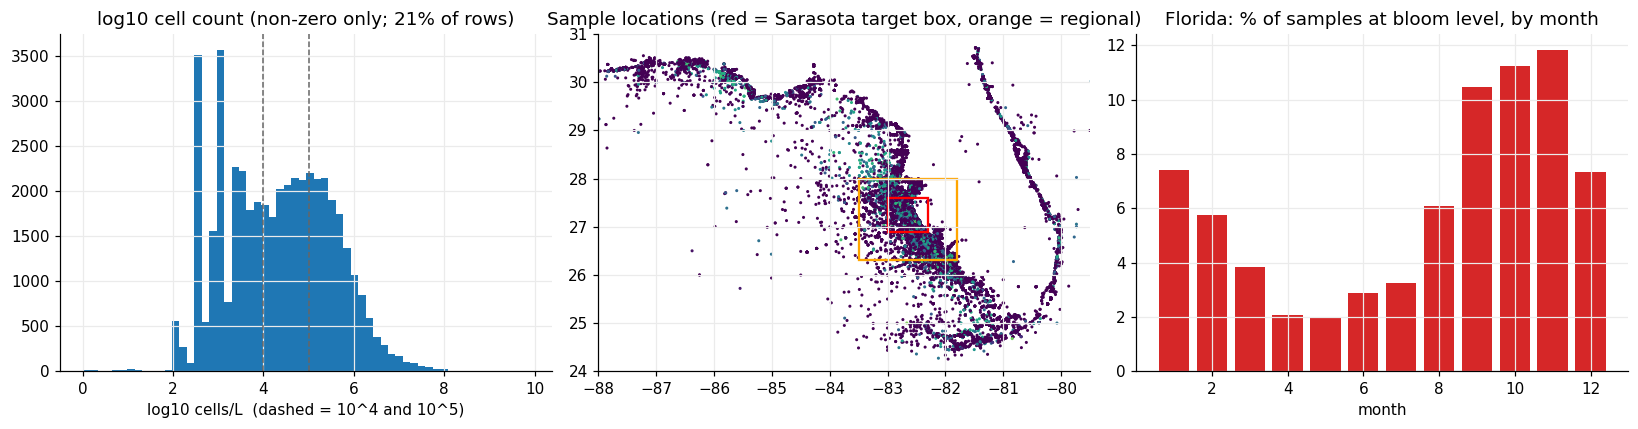

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
pos = habsos_raw.loc[habsos_raw["CELLCOUNT"] > 0, "CELLCOUNT"]
axes[0].hist(np.log10(pos), bins=60, color="tab:blue")
for x in (4, 5): axes[0].axvline(x, color="0.4", ls="--", lw=1)
axes[0].set_title(f"log10 cell count (non-zero only; {len(pos)/len(habsos_raw):.0%} of rows)")
axes[0].set_xlabel("log10 cells/L  (dashed = 10^4 and 10^5)")

sub = habsos_raw.sample(min(40000, len(habsos_raw)), random_state=0)
axes[1].scatter(sub["LONGITUDE"], sub["LATITUDE"], s=1, c=np.log10(sub["CELLCOUNT"] + 1), cmap="viridis")
for box, col in [(TARGET_BOX, "red"), (REGIONAL_BOX, "orange")]:
    axes[1].add_patch(plt.Rectangle((box["lon"][0], box["lat"][0]), np.diff(box["lon"])[0], np.diff(box["lat"])[0],
                                    fill=False, ec=col, lw=1.5))
axes[1].set_xlim(-88, -79.5); axes[1].set_ylim(24, 31)
axes[1].set_title("Sample locations (red = Sarasota target box, orange = regional)")

fl = habsos_raw[habsos_raw["STATE_ID"] == "FL"]
monthly_bloom = fl.groupby(fl["date"].dt.month)["CELLCOUNT"].apply(lambda s: (s >= 1e5).mean())
axes[2].bar(monthly_bloom.index, 100 * monthly_bloom.values, color="tab:red")
axes[2].set_title("Florida: % of samples at bloom level, by month"); axes[2].set_xlabel("month")
plt.tight_layout(); plt.show()

**What the figures show**

* **Left: cell-count distribution.** Counts range from about 100 to 10¹⁰ cells/L, so they are log10-transformed for plotting and modelling. On a normal scale the largest blooms would hide everything else. The x-axis shows log10 cells/L, where each step is ten times more cells (2 = 100, 4 = 10,000, 5 = 100,000). The y-axis shows how many samples fall in each bin. Most samples (79 %) contain no *K. brevis* and are not plotted, since log10(0) is undefined. Of those that do, about a third are at bloom level (≥ 10⁵, right dashed line; the left dashed line marks 10⁴).
* **Middle: sample locations.** The map shows where samples were taken, so it's clear which ones fall near Sarasota. The x-axis is longitude and the y-axis is latitude. Each dot is one sample, from a random 40,000 so the map stays readable. Colour shows log10(count + 1), from purple (no cells) to yellow (high counts); the + 1 lets zero counts be plotted. 97 % of samples are from Florida (the rest from Texas, Alabama and Mississippi). Sampling is densest along the southwest coast, around the regional box (orange) and the Sarasota target box (red).
* **Right: bloom season.** The chart shows when in the year blooms occur, using Florida samples only since they are 97 % of the data. The x-axis is the month (1 = January). The y-axis is the percentage of that month's samples at bloom level (≥ 10⁵ cells/L). Blooms are most common in **September–November** (10–12 % of samples) and least common in April–May (about 2 %). This seasonal cycle is what the seasonal-climatology baseline captures, and why month of year is a candidate feature.

**How often is the Sarasota box sampled, and where?**

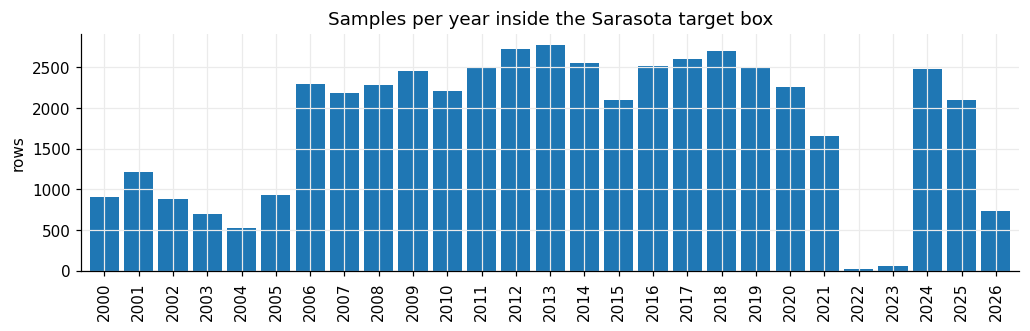

DESCRIPTION
Bay Dock (Sarasota Bay)                                5075
New Pass Dock (Sarasota Bay)                           4871
Venice Fishing Pier                                    1153
Venice Beach                                           1031
Anna Maria Island Rod & Reel Pier (Lower Tampa Bay)     952
Nokomis Beach                                           947
Englewood Beach                                         937
Longboat Pass Boat Ramp (Sarasota Bay)                  932
South Lido Park                                         892
North Jetty                                             879
Name: count, dtype: int64


In [9]:
tgt_raw = habsos_raw[is_in_box(habsos_raw["LATITUDE"], habsos_raw["LONGITUDE"], TARGET_BOX)]
plot_per_year(tgt_raw.loc[tgt_raw["date"] >= "2000", "date"], "Samples per year inside the Sarasota target box")
plt.show()
print(tgt_raw["DESCRIPTION"].value_counts().head(10))

### 1.5 Findings

* **Only one organism.** Every row is *Karenia brevis*, so this file can forecast red tide but not other HAB types.
* **Most samples found no *K. brevis*.** In 79 % of water samples (172,626 of 219,152) none were detected (`CELLCOUNT` = 0). The classes are therefore imbalanced, so models are judged on macro-F1 and bloom recall, not accuracy.
* **Counts span about eight orders of magnitude** (≈ 100 to 7.7 × 10⁹ cells/L), so they are log10-transformed for plotting and modelling (1.4).
* **`CATEGORY` and `CELLCOUNT` agree.** The category ranges don't overlap and edge values go up a class (1.3), so the label can come straight from `CELLCOUNT`.
* **The forecast has three classes:** no bloom (< 10⁴), at risk (10⁴–10⁵) and bloom (≥ 10⁵ cells/L). These are HABSOS's five categories merged as in Medina et al. (1.3).
* **The cell count is never missing.** Salinity and water temperature, however, are *both* missing in ~44 % of rows. An earlier team cleaning rule dropped those rows and lost ~95k valid labels; they are kept here.
* **Sampling is concentrated near Sarasota.** 97 % of samples are from Florida and are densest on the southwest coast. Two Sarasota Bay sites (Bay Dock and New Pass Dock) supply about 10,000 samples.
* **Red tide is seasonal.** In Florida, bloom-level samples are most common in September–November (10–12 % of samples), stay elevated from August to January, and drop to about 2 % in April–May.
* **Sampling in the Sarasota box nearly stops in 2022–2023**, the same years the airport wind data begins (§5).

### 1.6 Cleaning, step by step
Each step shows what it removes and why, then applies it. Rows are only removed when they are wrong or irrelevant; a few out-of-range values are blanked instead.

In [10]:
name = "habsos_cellcounts"
log_step(name, "raw file", habsos_raw)

#### Step 1 — Keep rows with a valid date and cell count
A row without a date or a count can't become a label. (Check 1.2 found none, so this is a safety net.)

In [11]:
h1 = habsos_raw.dropna(subset=["date", "CELLCOUNT"])
show_step(name, habsos_raw, h1, "valid date + cell count")

valid date + cell count: 219,152 -> 219,152 rows  (removed 0)


#### Step 2 — Keep counts the provider marked as good (QA flag = 1)
`CELLCOUNT_QA` is HABSOS's quality flag for the cell count: 1 = good, 4 = exceeds normals, 5 = value converted by script, 9 = no data [1]. Only two values occur here: 1 (218,960 rows) and 5 (192 rows). All 192 flag-5 rows are Texas samples from 2023, and they include the file's largest count (7.7 × 10⁹ cells/L). Only flag-1 rows are kept. This removes under 0.1 % of the data and no samples near Sarasota.

**Source**
1. NOAA NCEI, *HABSOS Data Dictionary*, NCEI Accession 0120767 (v8.8), Support Documents. https://www.ncei.noaa.gov/data/oceans/archive/arc0069/0120767/8.8/data/0-data/Support%20Documents/HABSOS_Data_Dictionary.xlsx

In [12]:
print(h1["CELLCOUNT_QA"].value_counts().rename("rows"))
h2 = h1[h1["CELLCOUNT_QA"] == 1]
show_step(name, h1, h2, "QA flag == 1")

CELLCOUNT_QA
1    218960
5       192
Name: rows, dtype: int64
QA flag == 1: 219,152 -> 218,960 rows  (removed 192)


#### Step 3 — Remove duplicate samples
The same sample sometimes appears twice (same location, date, depth and count) under two record IDs or site names — a re-entry, not a second measurement. Left in, it would count twice in weekly statistics. Example pairs:

In [13]:
dups = h2[h2.duplicated(dup_key, keep=False)].sort_values(dup_key)
display(dups[dup_key + ["DESCRIPTION", "OBJECTID"]].head(6))
h3 = h2.drop_duplicates(dup_key)
show_step(name, h2, h3, "drop duplicates")

,LATITUDE,LONGITUDE,SAMPLE_DATE,SAMPLE_DEPTH,CELLCOUNT,DESCRIPTION,OBJECTID
67428,24.4792,-81.7163,2005-11-30 00:00:00,0.5,71000.0,Florida Keys; Boca Chica Channel; 6 mi S of,67542
67438,24.4792,-81.7163,2005-11-30 00:00:00,0.5,71000.0,WS-2,67552
67427,24.4793,-81.7162,2005-11-30 00:00:00,0.5,64000.0,Florida Keys; Boca Chica Channel; 6 mi S of,67541
67437,24.4793,-81.7162,2005-11-30 00:00:00,0.5,64000.0,WS-1,67551
67174,24.5755,-81.4103,2005-11-14 00:00:00,0.5,0.0,Florida Keys,67288
67175,24.5755,-81.4103,2005-11-14 00:00:00,0.5,0.0,Florida Keys,67289


drop duplicates: 218,960 -> 217,024 rows  (removed 1,936)


#### Step 4 — Keep surface samples (≤ 1 m, or depth not recorded)
*K. brevis* is monitored at the surface, so deeper samples (down to 1,000 m) describe a different water layer from the beach and bay conditions being forecast.

* **Protocol:** FWRI samples about 0.5 m below the surface [1], which is also the median depth in this file.
* **Literature:** Li et al. (2021) use only near-surface counts [2]. Medina, reviewing a HABSOS-based *K. brevis* model, asked whether samples below a certain depth were excluded and whether results applied only "within one meter of the surface" [3].
* **Blank depth:** HABSOS states that a missing depth means a near-surface sample [4], so those rows are kept.

**Sources**
1. FWC Fish and Wildlife Research Institute, *HAB sampling protocol for phytoplankton* (Feb 2019), NCEI Accession 0120767 Support Documents. https://www.ncei.noaa.gov/data/oceans/archive/arc0069/0120767/8.8/data/0-data/Support%20Documents/FWRI-HAB%20sampling%20protocol%20for%20phytoplankton%20(Feb2019).pdf
2. Li, M. F., Glibert, P. M., & Lyubchich, V. (2021). Machine learning classification algorithms for predicting *Karenia brevis* blooms on the West Florida Shelf. *Journal of Marine Science and Engineering*, 9(9), 999. https://doi.org/10.3390/jmse9090999
3. Medina, M. (2023, 13 July). Reviewer report on Guirhem, G. L., Baker, L., & Moraga, P., Modeling the spatio-temporal distribution of *Karenia brevis* blooms in the Gulf of Mexico. *F1000Research*, 12, 633. In the "Open Peer Review" panel, Methods comments: "Are the results only relevant for K. brevis near the surface (e.g. within one meter of the surface)?" https://f1000research.com/articles/12-633
4. NOAA NCEI, *HABSOS Data Dictionary*, NCEI Accession 0120767 (v8.8), "Additional statements" (row 31): "If a SAMPLE_DEPTH value is null it is assumed to be collected very near to the surface." https://www.ncei.noaa.gov/data/oceans/archive/arc0069/0120767/8.8/data/0-data/Support%20Documents/HABSOS_Data_Dictionary.xlsx

In [14]:
print("Sample depth (m):", h3["SAMPLE_DEPTH"].describe().round(1).to_dict())
print("Depth not recorded:", h3["SAMPLE_DEPTH"].isna().sum())
h4 = h3[h3["SAMPLE_DEPTH"].isna() | (h3["SAMPLE_DEPTH"] <= 1)]
show_step(name, h3, h4, "surface samples (<= 1 m)")

Sample depth (m): {'count': 211096.0, 'mean': 2.0, 'std': 7.8, 'min': 0.0, '25%': 0.5, '50%': 0.5, '75%': 0.5, 'max': 1000.3}
Depth not recorded: 5928
surface samples (<= 1 m): 217,024 -> 189,686 rows  (removed 27,338)


#### Step 5 — Keep the region around Sarasota
Samples from Texas, Alabama, the Panhandle and the Keys don't describe Sarasota conditions. Only samples in a **regional box** are kept (lat 26.3–28.0, lon −83.5 to −81.8) — wider than the Sarasota target box, because blooms start offshore and are carried to the coast, so "what's happening nearby" is a useful feature (sources in Step 7).

In [15]:
print("Rows by state before:", h4["STATE_ID"].value_counts().to_dict())
h5 = h4[is_in_box(h4["LATITUDE"], h4["LONGITUDE"], REGIONAL_BOX)].copy()
show_step(name, h4, h5, "inside regional box")

Rows by state before: {'FL': 182716, 'AL': 3043, 'TX': 2880, 'MS': 1047}


inside regional box: 189,686 -> 114,545 rows  (removed 75,141)


#### Step 6 — Blank out-of-range salinity and water-temperature values (rows kept)
Salinity outside 0–45 and water temperature outside 5–40 °C are treated as errors. This is the **gross range test**, a required check for ocean temperature and salinity data [1]: any value outside a minimum–maximum span is flagged. The manual's example span is −2.5–40 °C for temperature and 2–41 for salinity, and it lets each operator adjust the span using local knowledge [1]. Two bounds here differ from the example:

* **Temperature lower bound is 5 °C instead of −2.5 °C.** In this data, the only water temperatures below 5 °C are 297 readings between 0.6 and 4.2 °C; every other reading is 6.0 °C or warmer. All 297 carry HABSOS flag 5, "value converted by script" [2]. A 5 °C bound removes exactly those flagged readings and nothing else. The −2.5 °C example bound would keep them.
* **Salinity lower bound is 0 instead of 2.** 118 samples have salinity between 0 and 2. Using 2 would remove them, while 0 keeps them. The upper bound of 45 removes one value, 308, which HABSOS flags as 4, "exceeds normals" [2].

Only the flagged *value* is set to missing; the row and its cell count stay.

**Sources**
1. U.S. Integrated Ocean Observing System (2020). *Manual for Real-Time Quality Control of In-situ Temperature and Salinity Data*, Version 2.1, Test 4 (Gross Range Test), p. 17. https://doi.org/10.25923/x02m-m555
2. NOAA NCEI, *HABSOS Data Dictionary*, NCEI Accession 0120767 (v8.8): QA flags "1=good 4=exceeds normals 5=value converted by script 9=no data". https://www.ncei.noaa.gov/data/oceans/archive/arc0069/0120767/8.8/data/0-data/Support%20Documents/HABSOS_Data_Dictionary.xlsx

In [16]:
bad_sal = h5["SALINITY"].notna() & ~h5["SALINITY"].between(0, 45)
bad_temp = h5["WATER_TEMP"].notna() & ~h5["WATER_TEMP"].between(5, 40)
print(f"salinity values blanked: {bad_sal.sum()} | water-temp values blanked: {bad_temp.sum()}")
h5.loc[bad_sal, "SALINITY"] = np.nan
h5.loc[bad_temp, "WATER_TEMP"] = np.nan

salinity values blanked: 1 | water-temp values blanked: 297


#### Step 7 — Flag which samples are inside the Sarasota target box
The **target box** (lat 26.9–27.6, lon −83.0 to −82.3; Anna Maria Island to Englewood) defines the label. Samples elsewhere in the regional box (Step 5) stay in the table as "nearby" features.

* **Same design as Medina et al. [1].** They forecast inside a small target domain (Charlotte Harbor), using *K. brevis* features from a larger feature domain that contains it and extends north to Sarasota Bay: "The K. brevis feature domain is therefore a superset of the K. brevis target domain."
* **Why the wider area helps.** *K. brevis* blooms start offshore, 18–74 km from the coast, and winds and currents carry them to shore [2][3][4]. Counts in the wider area can therefore rise before Sarasota's, which makes them useful early-warning features.
* **Matches the satellite data.** The project's chlorophyll file covers lat 26.5–28.0, lon −83.5 to −81.8. The regional box uses the same longitudes and lat 26.3–28.0, so the satellite and cell-count data describe about the same area.

The exact edges of both boxes are a project choice.

**Sources**
1. Medina, M., Julian, P., Chin, N., & Davis, S. E. (2024). An early-warning forecast model for red tide (*Karenia brevis*) blooms on the southwest coast of Florida. *Harmful Algae*, 139, 102729, §2.1–2.2. https://doi.org/10.1016/j.hal.2024.102729
2. FWC Fish and Wildlife Research Institute, *About Florida red tide*: "Florida's red tides begin in nutrient-poor water 18 to 74 kilometers (11 to 46 miles) offshore." https://myfwc.com/research/redtide/general/about/
3. Steidinger, K. A. (2009). Historical perspective on *Karenia brevis* red tide research in the Gulf of Mexico. *Harmful Algae*, 8, 549–561. https://doi.org/10.1016/j.hal.2008.11.009
4. Weisberg, R., Liu, Y., Lembke, C., Hu, C., Hubbard, K., & Garrett, M. (2019). The coastal ocean circulation influence on the 2018 West Florida Shelf *K. brevis* red tide bloom. *Journal of Geophysical Research: Oceans*, 124, 2501–2512. https://doi.org/10.1029/2018JC014887

In [17]:
h5["in_target"] = is_in_box(h5["LATITUDE"], h5["LONGITUDE"], TARGET_BOX)
print(f"in target box: {h5['in_target'].sum():,} of {len(h5):,} samples")
log_step(name, "of which inside target box", int(h5["in_target"].sum()))

habsos = h5[["date", "LATITUDE", "LONGITUDE", "DESCRIPTION", "CELLCOUNT", "SALINITY", "WATER_TEMP", "in_target"]].rename(columns=str.lower)
habsos.head()

in target box: 53,193 of 114,545 samples


,date,latitude,longitude,description,cellcount,salinity,water_temp,in_target
0,1953-08-19,26.9345,-82.3535,Tom Adams Bridge (Lemon Bay),116000.0,NaN,NaN,True
2,1953-08-26,26.5334,-81.9796,Piney Point; Lee County,0.0,NaN,NaN,False
3,1953-08-26,27.4684,-82.6937,Cortez Bridge,178000.0,NaN,NaN,True
4,1953-09-03,27.3775,-82.5708,Sarasota Bay; 3 mi North of bridge,1732000.0,NaN,NaN,True
5,1953-09-03,27.3859,-82.6411,Longboat Key; middle; nearshore,600000.0,NaN,NaN,True


#### Deliberately *not* done
* **Did not drop rows missing salinity or water temperature** — the cell count (the label) is still valid in those rows.
* **Did not remove high cell counts as outliers** — counts in the millions are real blooms, the thing being predicted.
* **Did not read the label from `CATEGORY`.** It gives the same classes, but `CELLCOUNT` also covers the 856 rows without a category and allows a weekly maximum (1.3).
* **Did not fill gaps in time** — a week with no sample gets no label rather than a guessed one.
* **Did not scale or normalise** — that happens inside each model's training split, so test data never leaks into training.

### 1.7 Cleaning summary

In [18]:
display(summarise_cleaning(name, subset_steps=["of which inside target box"]))
del habsos_raw, sub, fl, h1, h2, h3, h4, dups

,step,rows,removed,% of raw
0,raw file,219152,0,100.0
1,valid date + cell count,219152,0,100.0
2,QA flag == 1,218960,192,99.9
3,drop duplicates,217024,"1,936",99.0
4,surface samples (<= 1 m),189686,"27,338",86.6
5,inside regional box,114545,"75,141",52.3
6,of which inside target box,53193,0,24.3


---
## 2. `ChlorophyllaConcentrationSarasota` + `_Dataset2` — satellite chlorophyll-a

| | File 1 (DS1) `ChlorophyllaConcentrationSarasota` | File 2 (DS2) `…_Dataset2` |
|---|---|---|
| **What** | Gap-filled 2 km satellite chlorophyll-a (mg/m³) | Satellite chlorophyll-a (mg/m³) on a coarser grid |
| **Source** | NOAA CoastWatch multi-sensor DINEOF product [1] | Not documented in the project files |
| **Coverage** | Jun 2020 – Sep 2026 | Jan 2010 – May 2022 |
| **Role** | Bloom biomass signal and chlorophyll anomaly [2][3] | Extends the record back to 2010 |

Chlorophyll measures **all** algae, not only *K. brevis*. NOAA's red-tide detection flags chlorophyll that rises above its recent baseline (a chlorophyll anomaly) [2][3]. The merge method follows `notebooks/merge_chlorophyll.ipynb` in the 1A repo.

**This section:** 2.1 load and first look · 2.2 data-quality checks · 2.3 which pixels are land, and how often is water seen? · 2.4 exploring the data · 2.5 findings · 2.6 cleaning and merging, step by step · 2.7 cleaning summary

**Sources**
1. NOAA CoastWatch, *NOAA MSL12 multi-sensor DINEOF global 2 km gap-filled chlorophyll*. https://coastwatch.noaa.gov/cwn/products/noaa-msl12-multi-sensor-dineof-global-2-km-gap-filled-products-chlorophyll-diffuse.html · Liu, X., & Wang, M. (2023). High spatial resolution gap-free global and regional ocean color products. *IEEE Transactions on Geoscience and Remote Sensing*, 61, 4204118. https://doi.org/10.1109/tgrs.2023.3271465
2. Stumpf, R. P., Culver, M. E., Tester, P. A., et al. (2003). Monitoring *Karenia brevis* blooms in the Gulf of Mexico using satellite ocean color imagery and other data. *Harmful Algae*, 2, 147–160. https://doi.org/10.1016/S1568-9883(02)00083-5
3. Tomlinson, M. C., Wynne, T. T., & Stumpf, R. P. (2009). An evaluation of remote sensing techniques for enhanced detection of the toxic dinoflagellate, *Karenia brevis*. *Remote Sensing of Environment*, 113, 598–609. https://doi.org/10.1016/j.rse.2008.11.003

### 2.1 Load and first look
One row per **pixel per day**: date, latitude, longitude, chlorophyll-a. Pixels with no reading (cloud, land, sun glint) have an empty value.

In [19]:
chl_raw = {}
for key, stem in [("DS1", "ChlorophyllaConcentrationSarasota"), ("DS2", "ChlorophyllaConcentrationSarasota_Dataset2")]:
    df = read_erddap(stem, usecols=["time", "latitude", "longitude", "chlor_a"],
                     dtype={"latitude": "float32", "longitude": "float32", "chlor_a": "float32"})
    df["date"] = pd.to_datetime(df["time"]).dt.tz_localize(None).dt.normalize()
    chl_raw[key] = df.drop(columns="time")
    print(f"{key}: {len(df):,} rows x {df.shape[1]} columns")
chl_raw["DS1"].head(3)

DS1: 4,202,008 rows x 5 columns


DS2: 7,010,094 rows x 5 columns


,latitude,longitude,chlor_a,date
0,27.99375,276.506256,NaN,2020-06-15
1,27.99375,276.543762,NaN,2020-06-15
2,27.99375,276.581238,NaN,2020-06-15


**Column overview** (DS1, then DS2):

In [20]:
display(profile_columns(chl_raw["DS1"]))
profile_columns(chl_raw["DS2"])

,dtype,missing,missing_%,distinct,example
latitude,float32,0,0.0,41,27.99375
longitude,float32,0,0.0,46,276.506256
chlor_a,float32,3162496,75.3,1028932,0.163719
date,datetime64[us],0,0.0,2228,2020-06-15 00:00:00


,dtype,missing,missing_%,distinct,example
latitude,float32,0,0.0,37,28.020832
longitude,float32,0,0.0,42,276.479187
chlor_a,float32,5663976,80.8,1270028,0.730671
date,datetime64[us],0,0.0,4511,2010-01-01 00:00:00


### 2.2 Data-quality checks

In [21]:
def chl_checks(d):
    lats, lons = np.sort(d["latitude"].unique()), np.sort(d["longitude"].unique())
    expected = pd.date_range(d["date"].min(), d["date"].max())
    return {
        "Rows": f"{len(d):,}",
        "Date range": f"{d['date'].min().date()} -> {d['date'].max().date()}",
        "Days missing from the daily series": len(expected) - d["date"].nunique(),
        "Grid (lat x lon)": f"{len(lats)} x {len(lons)}",
        "Grid spacing (degrees)": round(float(np.diff(lats).mean()), 4),
        "Longitude format": f"{lons.min():.2f} to {lons.max():.2f} (0-360 east)",
        "Empty chlorophyll values": f"{d['chlor_a'].isna().mean():.0%}",
        "Duplicate (date, lat, lon)": int(d.duplicated(["date", "latitude", "longitude"]).sum()),
        "Values below 0.01 (outside valid range)": int((d["chlor_a"] < 0.01).sum()),
        "Values at/above 99 (product's upper limit)": int((d["chlor_a"] >= 99).sum()),
        "Min / max chlorophyll": f"{d['chlor_a'].min():.3f} / {d['chlor_a'].max():.1f}",
    }
pd.DataFrame({k: chl_checks(d) for k, d in chl_raw.items()})

,DS1,DS2
Rows,"4,202,008","7,010,094"
Date range,2020-06-15 -> 2026-09-05,2010-01-01 -> 2022-05-31
Days missing from the daily series,46,23
Grid (lat x lon),41 x 46,37 x 42
Grid spacing (degrees),0.0375,0.0417
Longitude format,276.51 to 278.19 (0-360 east),276.48 to 278.19 (0-360 east)
Empty chlorophyll values,75%,81%
"Duplicate (date, lat, lon)",0,0
Values below 0.01 (outside valid range),20,0
Values at/above 99 (product's upper limit),10,10


### 2.3 Which pixels are land, and how often is water seen?
Pixels with no value on any day are land cells. The team checked these against a 1 km land map: all of DS1's never-valid cells and 97 % of DS2's are centred on land, and none is entirely water [1][2].

**Sources**
1. Biointerphase 1A, `notebooks/compare_chlorophyll_datasets.ipynb`, "Where do the NaNs come from?".
2. Karin, T. *global-land-mask* (Python package; GLOBE 1 km land/water map). https://github.com/toddkarin/global-land-mask

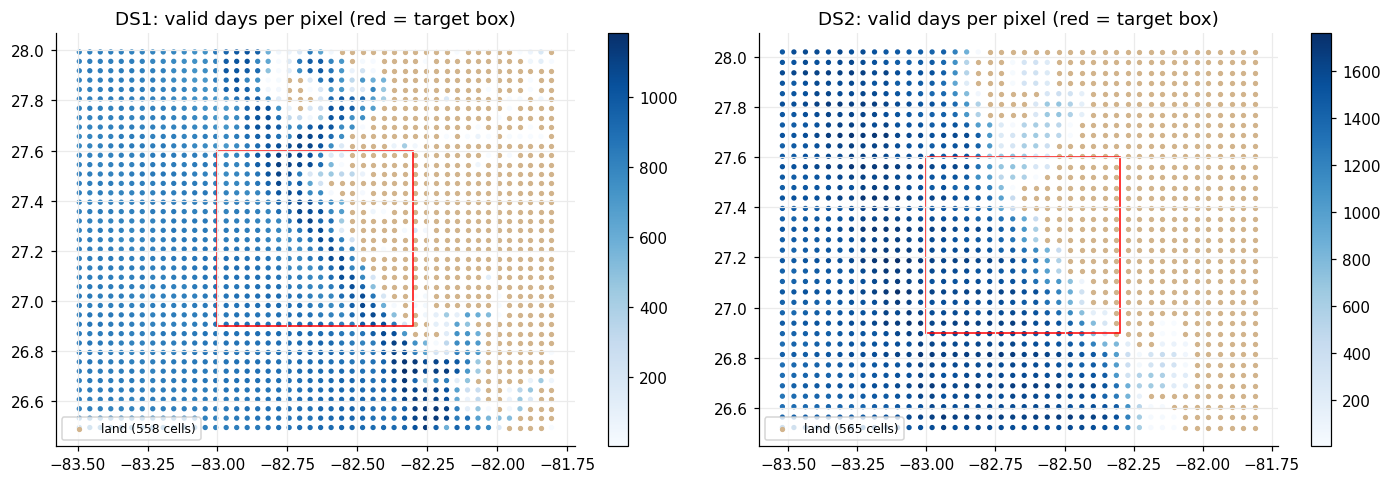

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (key, d) in zip(axes, chl_raw.items()):
    cov = d.groupby(["latitude", "longitude"])["chlor_a"].count().rename("days").reset_index()
    cov["longitude"] = cov["longitude"] - 360
    land = cov[cov["days"] == 0]
    sc = ax.scatter(cov.loc[cov.days > 0, "longitude"], cov.loc[cov.days > 0, "latitude"],
                    c=cov.loc[cov.days > 0, "days"], s=6, cmap="Blues")
    ax.scatter(land["longitude"], land["latitude"], s=6, c="tan", label=f"land ({len(land)} cells)")
    ax.add_patch(plt.Rectangle((TARGET_BOX["lon"][0], TARGET_BOX["lat"][0]), 0.7, 0.7, fill=False, ec="red"))
    ax.set_title(f"{key}: valid days per pixel (red = target box)"); ax.legend(loc="lower left", fontsize=8)
    plt.colorbar(sc, ax=ax)
plt.tight_layout(); plt.show()

**What the figures show**

* **Valid days per pixel, one map per file.** The x-axis is longitude and the y-axis is latitude. Each dot is a grid cell, coloured by the number of days it has a value (darker blue = more days). Tan dots never have a value and are treated as land: 558 cells in DS1 and 565 in DS2. The red rectangle is the Sarasota target box.
* Offshore pixels have values on the most days. Pixels next to the coast and inside the bays have far fewer.

### 2.4 Exploring the data
How does chlorophyll vary over time in each file, and do the two agree where they overlap (Jun 2020 – May 2022)?

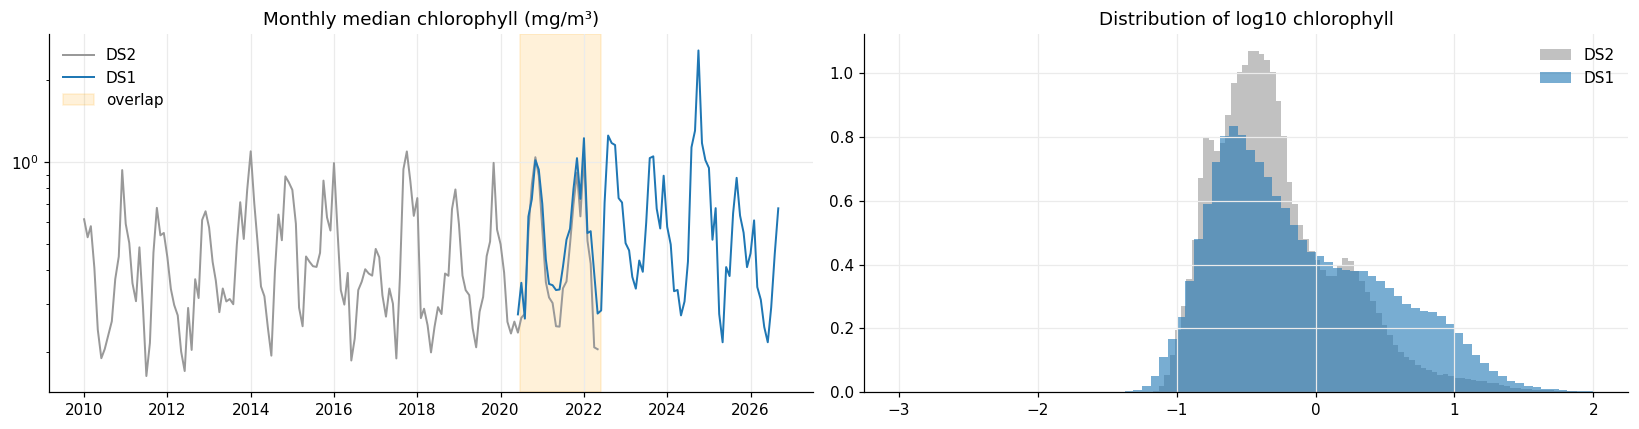

In [23]:
OVERLAP_START, OVERLAP_END = pd.Timestamp("2020-06-15"), pd.Timestamp("2022-05-31")
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for key, col in [("DS2", "0.6"), ("DS1", "tab:blue")]:
    d = chl_raw[key]
    m = d.groupby(d["date"].dt.to_period("M"))["chlor_a"].median()
    axes[0].plot(m.index.to_timestamp(), m.values, color=col, label=key, lw=1.3)
axes[0].axvspan(OVERLAP_START, OVERLAP_END, color="orange", alpha=0.15, label="overlap")
axes[0].set_yscale("log"); axes[0].set_title("Monthly median chlorophyll (mg/m³)"); axes[0].legend(frameon=False)
for key, col in [("DS2", "0.6"), ("DS1", "tab:blue")]:
    v = chl_raw[key]["chlor_a"].dropna()
    axes[1].hist(np.log10(v[v > 0]), bins=80, alpha=0.6, density=True, color=col, label=key)
axes[1].set_title("Distribution of log10 chlorophyll"); axes[1].legend(frameon=False)
plt.tight_layout(); plt.show()

**What the figures show**

* **Left: monthly median chlorophyll over time.** The x-axis is time and the y-axis is chlorophyll on a log scale, because values span several orders of magnitude. Grey is DS2, blue is DS1 and the orange band is the overlap. Both files rise and fall each year, and they track each other closely in the overlap.
* **Right: distribution of all values.** The x-axis is log10 chlorophyll (−1 = 0.1 mg/m³, 1 = 10 mg/m³) and the y-axis is the share of values (density). DS1 has more high values than DS2. This is why DS2 is adjusted to DS1's scale before the two are combined (Step 7).

**Is chlorophyll seasonal?** Pixel values inside the Sarasota target box, grouped by calendar month.

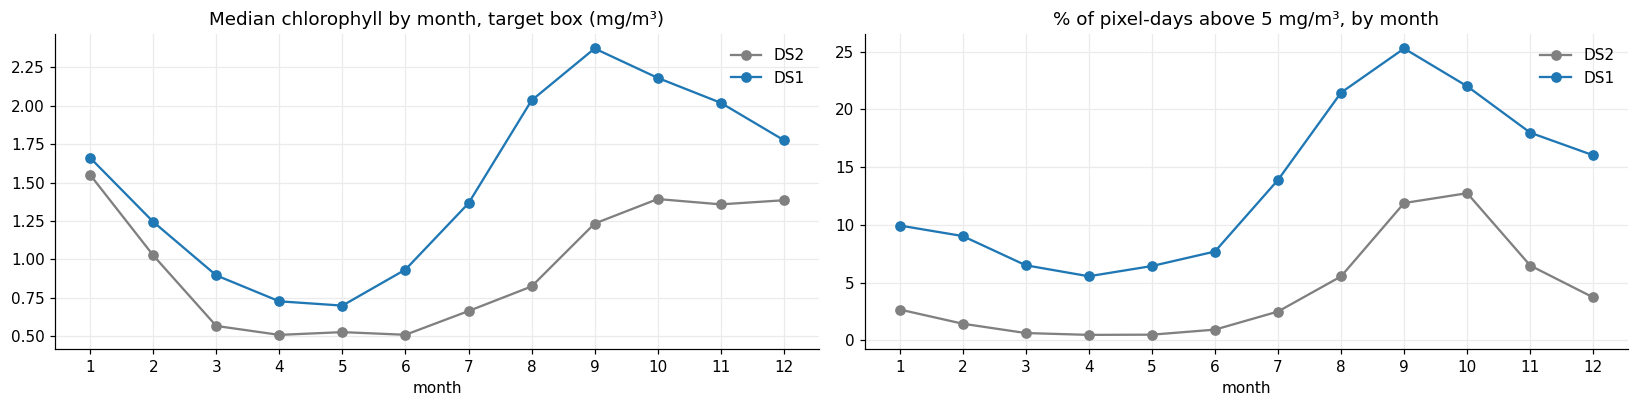

date                   1     2     3     4     5     6      7      8      9      10     11     12
DS2 median (mg/m³)   1.55  1.03  0.57  0.51  0.53  0.51   0.66   0.82   1.23   1.39   1.36   1.39
    % above 5 mg/m³  2.67  1.44  0.63  0.47  0.49  0.93   2.49   5.53  11.89  12.74   6.47   3.71
DS1 median (mg/m³)   1.66  1.24  0.90  0.73  0.70  0.93   1.37   2.04   2.37   2.18   2.02   1.78
    % above 5 mg/m³  9.94  9.03  6.50  5.55  6.43  7.69  13.88  21.45  25.27  21.99  17.98  16.02

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(15, 3.8))
season = {}
for key, col in [("DS2", "0.5"), ("DS1", "tab:blue")]:
    d = chl_raw[key].dropna(subset=["chlor_a"])
    d = d[(d["chlor_a"] >= 0.01) & is_in_box(d["latitude"], d["longitude"] - 360, TARGET_BOX)]
    g = d.groupby(d["date"].dt.month)["chlor_a"]
    season[key] = pd.DataFrame({"median (mg/m³)": g.median(), "% above 5 mg/m³": 100 * g.apply(lambda v: (v > 5).mean())})
    axes[0].plot(season[key].index, season[key]["median (mg/m³)"], "-o", color=col, label=key)
    axes[1].plot(season[key].index, season[key]["% above 5 mg/m³"], "-o", color=col, label=key)
axes[0].set_title("Median chlorophyll by month, target box (mg/m³)"); axes[0].set_xlabel("month")
axes[1].set_title("% of pixel-days above 5 mg/m³, by month"); axes[1].set_xlabel("month")
for ax in axes: ax.set_xticks(range(1, 13)); ax.legend(frameon=False)
plt.tight_layout(); plt.show()
pd.concat(season, axis=1).round(2).T

**What the figures show**

* **Left: median chlorophyll by month.** The x-axis is the month (1 = January) and the y-axis is the median pixel value in the target box (mg/m³). Both files are lowest in April–June and highest in August–November. In DS1 the median rises from 0.7 mg/m³ in May to 2.4 mg/m³ in September.
* **Right: share of high values by month.** The y-axis is the percentage of pixel-days above 5 mg/m³. High values are rare in April–May (about 5–6 % in DS1, under 1 % in DS2) and most common in September–October (25 % in DS1 in September, 13 % in DS2 in October).
* **The high-chlorophyll months match the red-tide peak** in the HABSOS cell counts (September–November, §1.4). Season (week of year) is therefore included as a feature in §10, so the model can separate the regular seasonal rise from unusual values.

### 2.5 Findings
* **Most raw rows are empty:** 75 % in DS1 and 81 % in DS2.
* **The two files use different grids** (DS1 0.0375°, DS2 0.0417°) **and read differently:** on matching pixel-days in the overlap, DS1 reads 7.5 % lower than DS2 at the median and has more high values. Stacking them unchanged would create a step in 2020.
* **Values sit at the product's limits.** The product's valid range is 0.001–100 mg/m³ [1]. DS1 has 20 values below 0.01 (7 exactly at 0.001), and both files have 10 values at or above 99.
* **Coastal and bay pixels have the fewest observations.**
* **Chlorophyll is seasonal:** lowest in April–June and highest in August–November, the same months as the red-tide peak (§1.4).

**Source**
1. NASA Ocean Biology Processing Group, *chlor_a* product metadata: valid_min = 0.001, valid_max = 100 mg m⁻³ (e.g. NOAA CoastWatch ERDDAP, https://coastwatch.pfeg.noaa.gov/erddap/info/erdMH1chla1day_R2022SQ/index.html).

### 2.6 Cleaning and merging, step by step
Steps 1–5 clean each file separately, Steps 6–8 merge them, and Step 9 keeps the Sarasota target box.

In [25]:
for key, d in chl_raw.items():
    log_step(f"chlorophyll {key}", "raw file", d)

#### Step 1 — Convert longitude to −180…180 (rows kept)
Both files store longitude as 0–360° east (e.g. 277.5). Every other dataset uses −180…180 (−82.5), so 360 is subtracted.

In [26]:
for key, d in chl_raw.items():
    d["longitude"] = (d["longitude"] - 360).round(5)
    print(f"{key}: longitude now {d['longitude'].min():.3f} to {d['longitude'].max():.3f}")
    log_step(f"chlorophyll {key}", "longitude converted to -180..180", d, "values changed, rows kept")

DS1: longitude now -83.494 to -81.806
DS2: longitude now -83.521 to -81.812


#### Step 2 — Blank values below 0.01 mg/m³ (rows kept)
The chlorophyll algorithm (OCx) is designed for 0.01–100 mg/m³ [1], so values below 0.01 are outside its design range. DS1 has 20 such values, 7 of them exactly at the product minimum of 0.001 (2.5). DS2's lowest value is 0.061, so none of its values are affected. Only the value is set to missing. This follows the team's chlorophyll comparison notebook [2].

**Sources**
1. NASA Ocean Biology Processing Group (2023). *Chlorophyll a — Algorithm Theoretical Basis Document*, v1.1: "The current polynomial expression for OCx spans four orders of magnitude (0.01 to 100 mg m⁻³)." https://oceandata.sci.gsfc.nasa.gov/files/atbd/atbd-obdaac-chlorophyll-a.pdf
2. Biointerphase 1A, `notebooks/compare_chlorophyll_datasets.ipynb` (section 2.5) and `notebooks/merge_chlorophyll.ipynb` (`LOW_LIMIT = 0.01`).

In [27]:
for key, d in chl_raw.items():
    low = d["chlor_a"] < 0.01
    print(f"{key}: {low.sum()} values below 0.01 -> missing")
    d.loc[low, "chlor_a"] = np.nan
    log_step(f"chlorophyll {key}", "values below 0.01 blanked", d, f"{low.sum()} values set to missing, rows kept")

DS1: 20 values below 0.01 -> missing
DS2: 0 values below 0.01 -> missing


#### Step 3 — Mark land cells and flag coastal water cells
* **Land:** cells with no value on any day are land (2.3) and are left out.
* **Distance to land:** for every water cell, the distance to the nearest land cell is computed.
* **Coastal flag:** DS1 water cells within 10 km of land are flagged `coastal`, not removed. Their values are less certain: a coastline pixel mixes land and water, and light from nearby land can contaminate water pixels (the adjacency effect) [1]. They are also observed less often: 19 % of days within 10 km of land, against 38–42 % farther out [2]. The flag keeps these pixels but marks them, so they feed a separate coastal-only chlorophyll feature.

**Sources**
1. Bulgarelli, B., & Zibordi, G. (2018). On the detectability of adjacency effects in ocean color remote sensing of mid-latitude coastal environments by SeaWiFS, MODIS-A, MERIS, OLCI, OLI and MSI. *Remote Sensing of Environment*, 209, 423–438. https://doi.org/10.1016/j.rse.2017.12.021
2. Biointerphase 1A, `notebooks/compare_chlorophyll_datasets.ipynb` (coverage by distance from land) and `notebooks/merge_chlorophyll.ipynb` (`COASTAL_KM = 10`).

In [28]:
def to_km(lat, lon):
    """Convert latitude/longitude to approximate x/y kilometres for distance lookups.

    One degree of latitude is ~111 km; a degree of longitude is shorter by cos(latitude),
    evaluated at Sarasota (~27.3 N). Accurate enough within this small area.

    Args:
        lat (array-like): Latitudes in degrees.
        lon (array-like): Longitudes in degrees.

    Returns:
        numpy.ndarray: Array of shape (n, 2) with [north km, east km] per point.
    """
    return np.c_[np.asarray(lat) * 111, np.asarray(lon) * 111 * np.cos(np.radians(27.3))]

water = {}
for key, d in chl_raw.items():
    cells = d.groupby(["latitude", "longitude"])["chlor_a"].count().rename("n_valid").reset_index()
    land, w = cells[cells["n_valid"] == 0], cells[cells["n_valid"] > 0].copy()
    w["km_to_land"] = cKDTree(to_km(land["latitude"], land["longitude"])).query(to_km(w["latitude"], w["longitude"]))[0]
    water[key] = w
    print(f"{key}: {len(w)} water cells, {len(land)} land cells")
    log_step(f"chlorophyll {key}", "land cells identified", d, f"{len(land)} land cells, {len(w)} water cells")
water["DS1"]["coastal"] = (water["DS1"]["km_to_land"] <= 10).astype("int8")
log_step("chlorophyll DS1", "coastal water cells flagged (<= 10 km)", chl_raw["DS1"],
         f"{water['DS1']['coastal'].sum()} of {len(water['DS1'])} water cells flagged, rows kept")
print(f"DS1 coastal water cells (<= 10 km from land): {water['DS1']['coastal'].sum()} of {len(water['DS1'])}")

DS1: 1328 water cells, 558 land cells


DS2: 989 water cells, 565 land cells
DS1 coastal water cells (<= 10 km from land): 239 of 1328


#### Step 4 — Keep only valid observations
Once land cells are known, empty pixel-days carry no information and are removed.

In [29]:
chl_obs = {}
for key, d in chl_raw.items():
    chl_obs[key] = d.dropna(subset=["chlor_a"]).reset_index(drop=True)
    show_step(f"chlorophyll {key}", d, chl_obs[key], "valid observations only")
    LOG[-1]["note"] = "empty pixel-days removed (land, cloud, glint)"

valid observations only: 4,202,008 -> 1,039,492 rows  (removed 3,162,516)
valid observations only: 7,010,094 -> 1,346,118 rows  (removed 5,663,976)


#### Step 5 — Flag values at the upper limit, add a log column (rows kept)
Values of 99 mg/m³ or more are at the product's maximum of 100 (2.5). They are kept but flagged, and left out when the two files are compared in Step 7. `log_chl` = log10(chlorophyll).

In [30]:
for key, d in chl_obs.items():
    d["chl_at_limit"] = (d["chlor_a"] >= 99).astype("int8")
    d["log_chl"] = np.log10(d["chlor_a"])
    print(f"{key}: {d['chl_at_limit'].sum()} values flagged at limit")
    log_step(f"chlorophyll {key}", "values >= 99 flagged, log10 column added", d, f"{d['chl_at_limit'].sum()} values flagged, rows kept")
ds1, ds2 = chl_obs["DS1"], chl_obs["DS2"]

DS1: 10 values flagged at limit
DS2: 10 values flagged at limit


#### Step 6 — Put DS2 on DS1's grid
Each DS1 water cell takes the values of its **nearest DS2 water pixel**, if one is within 3.5 km (a project choice, about one DS2 pixel width). DS2 pixels are larger, so one DS2 pixel can feed two DS1 cells, which is why the row count grows. DS1 cells with no DS2 pixel within 3.5 km get no DS2 values.

In [31]:
dist, idx = cKDTree(to_km(water["DS2"]["latitude"], water["DS2"]["longitude"])).query(
    to_km(water["DS1"]["latitude"], water["DS1"]["longitude"]))
grid_map = water["DS1"][["latitude", "longitude"]].assign(
    lat_ds2=water["DS2"]["latitude"].values[idx], lon_ds2=water["DS2"]["longitude"].values[idx], dist_km=dist)
grid_map = grid_map[grid_map["dist_km"] <= 3.5]
ds2_on1 = (ds2.rename(columns={"latitude": "lat_ds2", "longitude": "lon_ds2"})
              .merge(grid_map, on=["lat_ds2", "lon_ds2"]).drop(columns=["lat_ds2", "lon_ds2", "dist_km"]))
print(f"DS1 water cells with a DS2 partner: {len(grid_map)} of {len(water['DS1'])} (median distance {grid_map.dist_km.median():.1f} km)")
show_step("chlorophyll DS2", ds2, ds2_on1, "re-gridded onto DS1 cells")
LOG[-1]["note"] = f"nearest DS2 pixel within 3.5 km; {len(grid_map)} of {len(water['DS1'])} DS1 water cells matched"

DS1 water cells with a DS2 partner: 1205 of 1328 (median distance 1.8 km)
re-gridded onto DS1 cells: 1,346,118 -> 1,627,087 rows  (added 280,969)


#### Step 7 — Adjust DS2 to read like DS1 (quantile mapping)
Quantile mapping matches two datasets by their percentiles, and is a standard way to remove a systematic difference between two products [1]. On pixel-days where **both** files have a value (the 2020–2022 overlap), DS2's 1st–99th percentiles are matched to DS1's: DS2's 10th percentile becomes DS1's 10th percentile, and so on. Every DS2 value is then translated through that table. Row counts don't change; only DS2's values shift.

**Source**
1. Gudmundsson, L., Bremnes, J. B., Haugen, J. E., & Engen-Skaugen, T. (2012). Technical Note: Downscaling RCM precipitation to the station scale using statistical transformations – a comparison of methods. *Hydrology and Earth System Sciences*, 16, 3383–3390. https://doi.org/10.5194/hess-16-3383-2012

In [32]:
pairs = ds1.merge(ds2_on1, on=["date", "latitude", "longitude"], suffixes=("_ds1", "_ds2"))
pairs = pairs[(pairs["chl_at_limit_ds1"] == 0) & (pairs["chl_at_limit_ds2"] == 0)]
PCTS = np.linspace(0.01, 0.99, 99)
q2, q1 = np.quantile(pairs["log_chl_ds2"], PCTS), np.quantile(pairs["log_chl_ds1"], PCTS)

def apply_qmap(x: np.ndarray) -> np.ndarray:
    """Translate DS2 log-chlorophyll values onto DS1's scale (quantile mapping).

    Values inside the 1st-99th percentile range are interpolated through the
    percentile table; values beyond it are shifted by the end offset instead of
    extrapolated.

    Args:
        x (array-like): DS2 values of log10(chlorophyll-a).

    Returns:
        numpy.ndarray: Adjusted log10(chlorophyll-a) values on DS1's scale.

    Example:
        >>> apply_qmap(np.log10([0.3, 1.0, 5.0])).shape
        (3,)
    """
    x = np.asarray(x); y = np.interp(x, q2, q1)
    y = np.where(x < q2[0], x + (q1[0] - q2[0]), y)
    return np.where(x > q2[-1], x + (q1[-1] - q2[-1]), y)

gap = lambda a, b: (1 - 10 ** np.median(a - b)) * 100
print(f"matched pixel-days in the overlap: {len(pairs):,}")
print(f"DS1 reads {gap(pairs['log_chl_ds1'], pairs['log_chl_ds2']):.1f}% lower than DS2 before adjustment, "
      f"{gap(pairs['log_chl_ds1'], apply_qmap(pairs['log_chl_ds2'])):.1f}% after")
display(pd.DataFrame({"percentile": [10, 50, 90, 99],
                      "DS2 value (mg/m³)": 10 ** np.interp([0.1, 0.5, 0.9, 0.99], PCTS, q2),
                      "becomes (mg/m³)": 10 ** np.interp([0.1, 0.5, 0.9, 0.99], PCTS, q1)}).round(3))
ds2_on1["log_chl"] = apply_qmap(ds2_on1["log_chl"])
ds2_on1["chlor_a"] = (10 ** ds2_on1["log_chl"]).astype("float32")
log_step("chlorophyll DS2", "values adjusted to DS1 scale (quantile mapping)", ds2_on1,
         f"DS1-DS2 median gap {gap(pairs['log_chl_ds1'], pairs['log_chl_ds2']):.1f}% -> "
         f"{gap(pairs['log_chl_ds1'], apply_qmap(pairs['log_chl_ds2'])):.1f}%, rows kept")

matched pixel-days in the overlap: 147,146
DS1 reads 7.5% lower than DS2 before adjustment, -0.7% after


,percentile,DS2 value (mg/m³),becomes (mg/m³)
0,10,0.179,0.175
1,50,0.495,0.468
2,90,3.013,2.727
3,99,18.972,11.059


#### Step 8 — Combine: DS1 wherever it has a value, adjusted DS2 elsewhere
| Period | Value used |
|---|---|
| 2010 → Jun 2020 | adjusted DS2 |
| Jun 2020 → May 2022 (overlap) | DS1; adjusted DS2 only where DS1 is empty that day |
| Jun 2022 → 2026 | DS1 |

In [33]:
d2 = ds2_on1.merge(ds1[["date", "latitude", "longitude"]], on=["date", "latitude", "longitude"], how="left", indicator=True)
d2 = d2[d2["_merge"] == "left_only"].drop(columns="_merge")
cols = ["date", "latitude", "longitude", "chlor_a"]
chl_all = (pd.concat([ds1[cols].assign(source="ds1"), d2[cols].assign(source="ds2_adj")], ignore_index=True)
             .merge(water["DS1"][["latitude", "longitude", "coastal"]], on=["latitude", "longitude"], how="left"))
log_step("chlorophyll (merged)", "DS1 + adjusted DS2", chl_all,
         f"{(chl_all['source'] == 'ds1').sum():,} DS1 rows + {(chl_all['source'] == 'ds2_adj').sum():,} adjusted DS2 rows")
print(f"merged rows: {len(chl_all):,} | duplicate (date, lat, lon): {chl_all.duplicated(['date', 'latitude', 'longitude']).sum()}")
pd.crosstab(chl_all["date"].dt.year, chl_all["source"]).T

merged rows: 2,519,433 | duplicate (date, lat, lon): 0


date,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
source,,,,,,,,,,,,,,,,,
ds1,0,0,0,0,0,0,0,0,0,0,75514,158580,151494,162315,163800,195833,131956
ds2_adj,136134,147221,116286,129805,125977,124888,140741,140485,132516,126095,84240,55365,20188,0,0,0,0


#### Step 9 — Keep the Sarasota target box
Only pixels inside the target box (lat 26.9–27.6, lon −83.0 to −82.3; see §1 Step 7) feed the weekly features.

inside target box: 2,519,433 -> 502,775 rows  (removed 2,016,658)


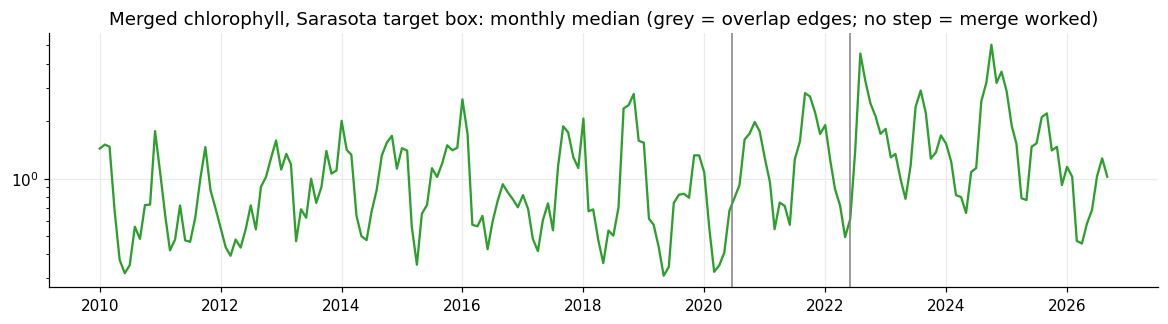

In [34]:
chl = chl_all[is_in_box(chl_all["latitude"], chl_all["longitude"], TARGET_BOX)].copy()
show_step("chlorophyll (merged)", chl_all, chl, "inside target box")
LOG[-1]["note"] = "lat 26.9-27.6, lon -83.0 to -82.3"
m = chl.groupby(chl["date"].dt.to_period("M"))["chlor_a"].median()
fig, ax = plt.subplots(figsize=(13, 3))
ax.plot(m.index.to_timestamp(), m.values, color="tab:green")
ax.axvline(OVERLAP_START, color="0.5", lw=1); ax.axvline(OVERLAP_END, color="0.5", lw=1)
ax.set_yscale("log"); ax.set_title("Merged chlorophyll, Sarasota target box: monthly median (grey = overlap edges; no step = merge worked)")
plt.show()

**What the figure shows**

* **Merged chlorophyll in the target box, monthly median.** The x-axis is time and the y-axis is chlorophyll (mg/m³, log scale). The grey lines mark the start and end of the overlap, where the series switches from adjusted DS2 to DS1.
* The series continues across both lines without a jump, so the adjustment in Step 7 removed the difference between the files.

#### Deliberately *not* done
* **Did not fill cloudy days.** A day with no observation stays missing instead of being interpolated.
* **Did not remove high values.** Bloom-level chlorophyll is the signal.
* **Did not average the two files.** DS1 is the newer, finer product, so it is used wherever it has a value.

### 2.7 Cleaning summary

In [35]:
for ds in ["chlorophyll DS1", "chlorophyll DS2", "chlorophyll (merged)"]:
    print(ds); display(summarise_cleaning(ds))
del chl_raw, chl_obs, ds1, ds2, ds2_on1, d2, pairs, chl_all

chlorophyll DS1


,step,rows,removed,% of raw,note
0,raw file,4202008,0,100.0,
1,longitude converted to -180..180,4202008,0,100.0,"values changed, rows kept"
2,values below 0.01 blanked,4202008,0,100.0,"20 values set to missing, rows kept"
3,land cells identified,4202008,0,100.0,"558 land cells, 1328 water cells"
4,coastal water cells flagged (<= 10 km),4202008,0,100.0,"239 of 1328 water cells flagged, rows kept"
5,valid observations only,1039492,"3,162,516",24.7,"empty pixel-days removed (land, cloud, glint)"
6,"values >= 99 flagged, log10 column added",1039492,0,24.7,"10 values flagged, rows kept"


chlorophyll DS2


,step,rows,removed,% of raw,note
0,raw file,7010094,0,100.0,
1,longitude converted to -180..180,7010094,0,100.0,"values changed, rows kept"
2,values below 0.01 blanked,7010094,0,100.0,"0 values set to missing, rows kept"
3,land cells identified,7010094,0,100.0,"565 land cells, 989 water cells"
4,valid observations only,1346118,"5,663,976",19.2,"empty pixel-days removed (land, cloud, glint)"
5,"values >= 99 flagged, log10 column added",1346118,0,19.2,"10 values flagged, rows kept"
6,re-gridded onto DS1 cells,1627087,"280,969 added",23.2,nearest DS2 pixel within 3.5 km; 1205 of 1328 DS1 water cells matched
7,values adjusted to DS1 scale (quantile mapping),1627087,0,23.2,"DS1-DS2 median gap 7.5% -> -0.7%, rows kept"


chlorophyll (merged)


,step,rows,removed,% of raw,note
0,DS1 + adjusted DS2,2519433,0,100.0,"1,039,492 DS1 rows + 1,479,941 adjusted DS2 rows"
1,inside target box,502775,"2,016,658",20.0,"lat 26.9-27.6, lon -83.0 to -82.3"
